# Machine Learning yanaşmaları:

1. Supervised learning - müəllimlə (nəzarətli) öyrənmə
    - Regression
    - Classification
2. Unsupervised learning - müəllimsiz (nəzarətsiz) öyrənmə
    - Clustering
    - Anomaly detection - qeyri adi (fərqli) halların araşdırılması
    - Dimensionality Reduction - ölçülüyün azaldılması
3. Reinforcement learning - mükafatlandırma(möhkəmləndirmə) ilə öyrənmə
4. Semi-Supervised learning
5. Self-Supervised learning

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Reqressiya alqoritminin öyrənmə mərhələləri
1. İlkin Emal
2. Dataların öyrənmə/test (train/test split) hissələrinə bölünməsi
3. Modelin və hiperparametrlərin seçilməsi
4. Parametrlərin optimizasiyası (öyrənmə)
5. Nəticələrin qiymətləndirilməsi (lazım gələrsə yenidən öyrənmə - retrain)
6. Kross validasiya (CV - cross validation) - daha stabil öyrənmə

In [2]:
FILE_PATH = 'Housing.csv'
data = pd.read_csv(FILE_PATH)

# EDA (Exploratory Data Analysis) - məlumatların ilkin analizi

In [3]:
data.head()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,1,42000,5850.0,3,1,2,yes,no,yes,no,no,1.0,no
1,2,38500,4000.0,2,1,1,yes,no,no,no,no,0.0,no
2,3,49500,3060.0,3,1,1,yes,no,no,no,no,0.0,no
3,4,60500,6650.0,3,1,2,yes,yes,no,no,no,0.0,no
4,5,61000,6360.0,2,1,1,yes,no,no,no,no,0.0,no


In [4]:
data.tail()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
541,542,91500,4800.0,3,2,4,yes,yes,no,no,yes,0.0,no
542,543,94000,6000.0,3,2,4,yes,no,no,no,yes,0.0,no
543,544,103000,6000.0,3,2,4,yes,yes,no,no,yes,1.0,no
544,545,105000,6000.0,3,2,2,yes,yes,no,no,yes,1.0,no
545,546,105000,6000.0,3,1,2,yes,no,no,no,yes,1.0,no


In [5]:
data.sample(5)

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
70,71,45000,4095.0,2,1,1,yes,no,no,no,no,2.0,no
100,101,57000,4500.0,3,2,2,no,no,yes,no,yes,0.0,no
342,343,80000,10500.0,2,1,1,yes,no,no,no,no,1.0,no
404,405,80000,6600.0,4,2,1,yes,no,yes,no,no,0.0,yes
118,119,106500,4300.0,3,2,2,yes,no,yes,no,no,1.0,no


In [6]:
data.shape

(546, 13)

In [7]:
data.dtypes

rownames      int64
price         int64
lotsize     float64
bedrooms      int64
bathrms       int64
stories       int64
driveway        str
recroom         str
fullbase        str
gashw           str
airco           str
garagepl    float64
prefarea        str
dtype: object

In [8]:
data.isna().sum()

rownames    0
price       0
lotsize     5
bedrooms    0
bathrms     0
stories     0
driveway    2
recroom     2
fullbase    0
gashw       0
airco       5
garagepl    2
prefarea    2
dtype: int64

In [9]:
data.describe()

,rownames,price,lotsize,bedrooms,bathrms,stories,garagepl
count,546.000000,546.000000,541.000000,546.000000,546.000000,546.000000,544.000000
mean,273.500000,68121.597070,5160.611830,2.965201,1.285714,1.807692,0.694853
std,157.760895,26702.670926,2175.141222,0.737388,0.502158,0.868203,0.861864
min,1.000000,25000.000000,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,137.250000,49125.000000,3584.000000,2.000000,1.000000,1.000000,0.000000
50%,273.500000,62000.000000,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,409.750000,82000.000000,6360.000000,3.000000,2.000000,2.000000,1.000000
max,546.000000,190000.000000,16200.000000,6.000000,4.000000,4.000000,3.000000


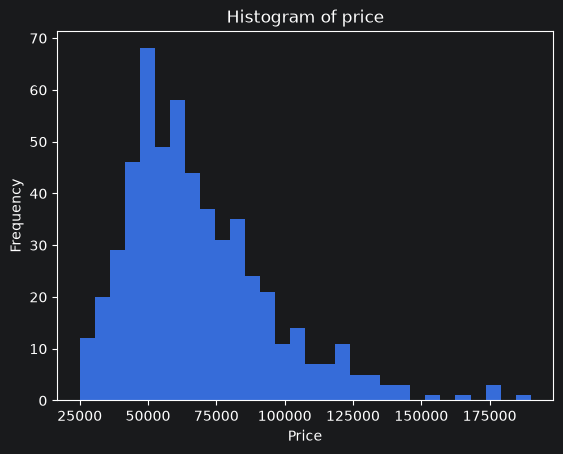

In [10]:
plt.figure()
plt.hist(data['price'], bins=30)
plt.title('Histogram of price')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

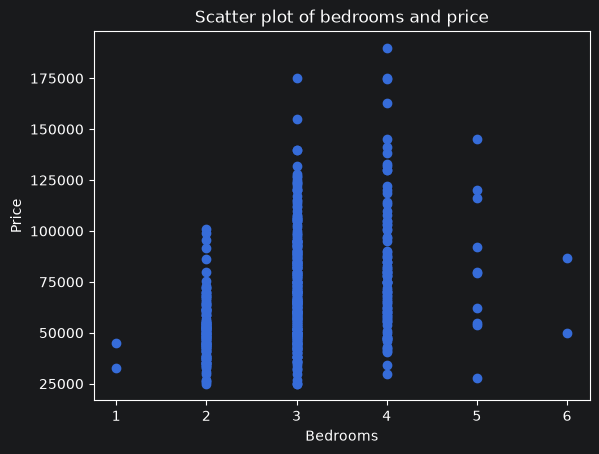

In [11]:
plt.scatter(data['bedrooms'], data['price'])
plt.title('Scatter plot of bedrooms and price')
plt.xlabel('Bedrooms')
plt.ylabel('Price')
plt.show()

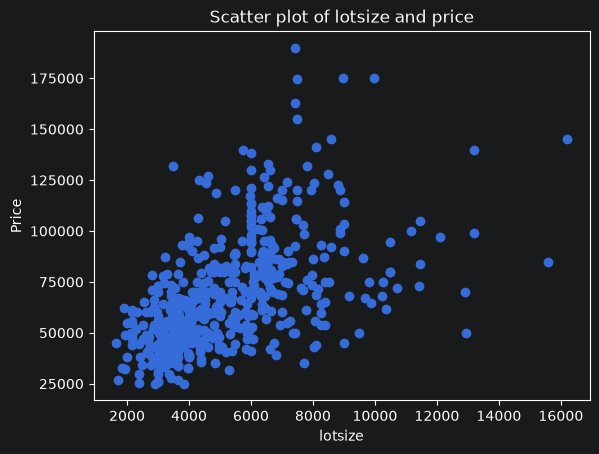

In [12]:
plt.scatter(data['lotsize'], data['price'])
plt.title('Scatter plot of lotsize and price')
plt.xlabel('lotsize')
plt.ylabel('Price')
plt.show()

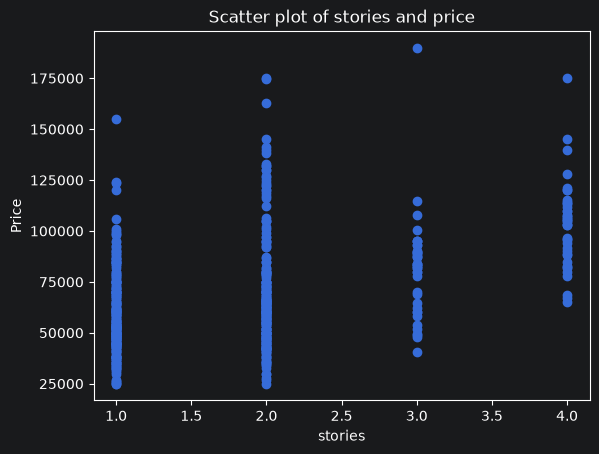

In [13]:
plt.scatter(data['stories'], data['price'])
plt.title('Scatter plot of stories and price')
plt.xlabel('stories')
plt.ylabel('Price')
plt.show()

In [14]:
target_col = 'price'
numeric_cols = [
    'lotsize',
    'bedrooms',
    'bathrms',
    'stories',
    'garagepl'
]

potential_cols = [
    'driveway',
    'recroom',
    'fullbase',
    'gashw',
    'airco',
    'prefarea'
]


In [15]:
categorical_cols = [c for c in potential_cols if c in data.columns]
all_used_cols = numeric_cols + categorical_cols + [target_col]
data = data[all_used_cols].copy()

In [16]:
data.head(10)

,lotsize,bedrooms,bathrms,stories,garagepl,driveway,recroom,fullbase,gashw,airco,prefarea,price
0,5850.0,3,1,2,1.0,yes,no,yes,no,no,no,42000
1,4000.0,2,1,1,0.0,yes,no,no,no,no,no,38500
2,3060.0,3,1,1,0.0,yes,no,no,no,no,no,49500
3,6650.0,3,1,2,0.0,yes,yes,no,no,no,no,60500
4,6360.0,2,1,1,0.0,yes,no,no,no,no,no,61000
5,4160.0,3,1,1,0.0,yes,yes,yes,no,yes,no,66000
6,3880.0,3,2,2,2.0,yes,no,yes,no,no,no,66000
7,4160.0,3,1,3,0.0,yes,no,no,no,no,no,69000
8,4800.0,3,1,1,0.0,yes,yes,yes,no,no,no,83800
9,5500.0,3,2,4,1.0,yes,yes,no,no,NaN,no,88500


# - .factorize(series)

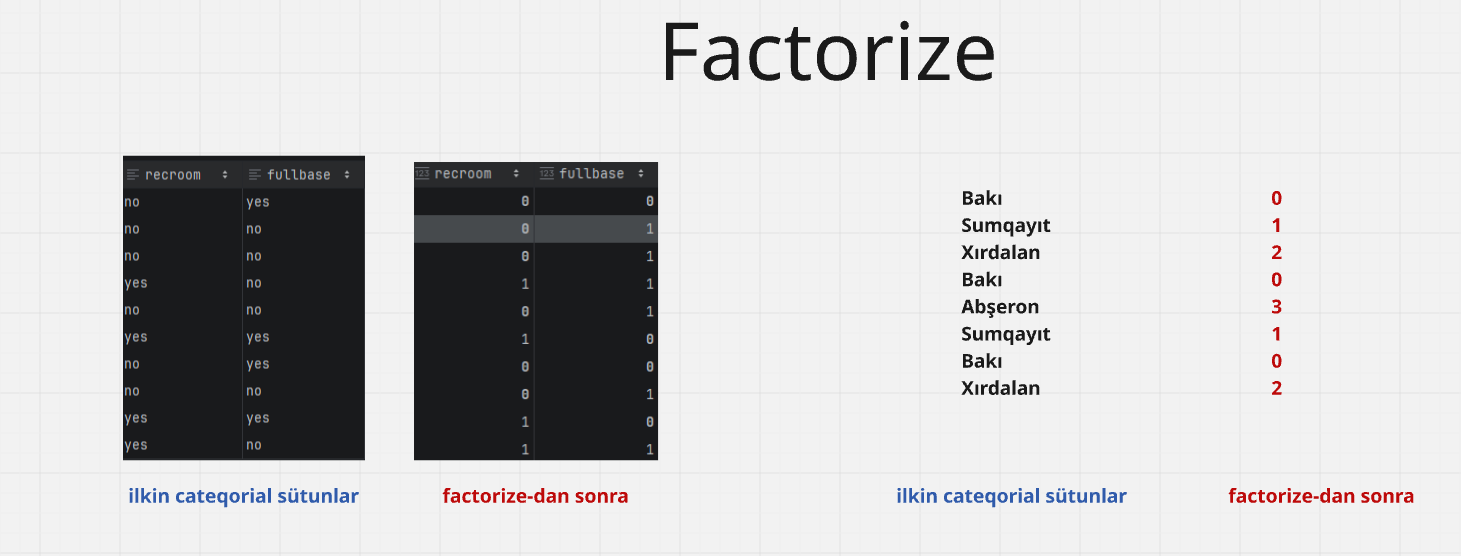

In [17]:
data_factorized = data.copy()
factorize_map = {}
for col in categorical_cols:
    codes, uniques = pd.factorize(data[col])
    data_factorized[col] = codes
    factorize_map[col] = list(uniques)
factorize_map

{'driveway': ['yes', 'no'],
 'recroom': ['no', 'yes'],
 'fullbase': ['yes', 'no'],
 'gashw': ['no', 'yes'],
 'airco': ['no', 'yes'],
 'prefarea': ['no', 'yes']}

In [18]:
data_factorized.head(10)

,lotsize,bedrooms,bathrms,stories,garagepl,driveway,recroom,fullbase,gashw,airco,prefarea,price
0,5850.0,3,1,2,1.0,0,0,0,0,0,0,42000
1,4000.0,2,1,1,0.0,0,0,1,0,0,0,38500
2,3060.0,3,1,1,0.0,0,0,1,0,0,0,49500
3,6650.0,3,1,2,0.0,0,1,1,0,0,0,60500
4,6360.0,2,1,1,0.0,0,0,1,0,0,0,61000
5,4160.0,3,1,1,0.0,0,1,0,0,1,0,66000
6,3880.0,3,2,2,2.0,0,0,0,0,0,0,66000
7,4160.0,3,1,3,0.0,0,0,1,0,0,0,69000
8,4800.0,3,1,1,0.0,0,1,0,0,0,0,83800
9,5500.0,3,2,4,1.0,0,1,1,0,-1,0,88500


# One-Hot Encoder OHE

In [19]:
data_onehot = pd.get_dummies(data, columns=categorical_cols, drop_first=True)
data_onehot.head(10)

,lotsize,bedrooms,bathrms,stories,garagepl,price,driveway_yes,recroom_yes,fullbase_yes,gashw_yes,airco_yes,prefarea_yes
0,5850.0,3,1,2,1.0,42000,True,False,True,False,False,False
1,4000.0,2,1,1,0.0,38500,True,False,False,False,False,False
2,3060.0,3,1,1,0.0,49500,True,False,False,False,False,False
3,6650.0,3,1,2,0.0,60500,True,True,False,False,False,False
4,6360.0,2,1,1,0.0,61000,True,False,False,False,False,False
5,4160.0,3,1,1,0.0,66000,True,True,True,False,True,False
6,3880.0,3,2,2,2.0,66000,True,False,True,False,False,False
7,4160.0,3,1,3,0.0,69000,True,False,False,False,False,False
8,4800.0,3,1,1,0.0,83800,True,True,True,False,False,False
9,5500.0,3,2,4,1.0,88500,True,True,False,False,False,False


In [24]:
data[numeric_cols].describe()

,lotsize,bedrooms,bathrms,stories,garagepl
count,541.000000,546.000000,546.000000,546.000000,544.000000
mean,5160.611830,2.965201,1.285714,1.807692,0.694853
std,2175.141222,0.737388,0.502158,0.868203,0.861864
min,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3584.000000,2.000000,1.000000,1.000000,0.000000
50%,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,6360.000000,3.000000,2.000000,2.000000,1.000000
max,16200.000000,6.000000,4.000000,4.000000,3.000000


# Scaler
1. MinMaxScaler
$$
x' = \frac{x - x_{min}}{x_{max} - x_{min}}
$$
2. StandardScaler
$$
x' = \frac{x - \mu}{\sigma}
$$

In [27]:
num_demo = data[numeric_cols].copy()
min_max_scaler = MinMaxScaler()
std_scaler = StandardScaler()
numeric_demo_mms = pd.DataFrame(min_max_scaler.fit_transform(num_demo), columns=numeric_cols)
numeric_demo_std = pd.DataFrame(std_scaler.fit_transform(num_demo), columns=numeric_cols)


In [28]:
numeric_demo_mms.head()

,lotsize,bedrooms,bathrms,stories,garagepl
0,0.288660,0.4,0.0,0.333333,0.333333
1,0.161512,0.2,0.0,0.000000,0.000000
2,0.096907,0.4,0.0,0.000000,0.000000
3,0.343643,0.4,0.0,0.333333,0.000000
4,0.323711,0.2,0.0,0.000000,0.000000


In [29]:
numeric_demo_std.head()

,lotsize,bedrooms,bathrms,stories,garagepl
0,0.317233,0.047235,-0.569495,0.221704,0.354381
1,-0.534074,-1.310147,-0.569495,-0.931157,-0.806963
2,-0.966630,0.047235,-0.569495,-0.931157,-0.806963
3,0.685365,0.047235,-0.569495,0.221704,-0.806963
4,0.551917,-1.310147,-0.569495,-0.931157,-0.806963


# SimpleImputer
- mean
- median
- most_frequent
- constant

In [32]:
data_impute_demo = data.copy()
data_impute_demo.head(15)

,lotsize,bedrooms,bathrms,stories,garagepl,driveway,recroom,fullbase,gashw,airco,prefarea,price
0,5850.0,3,1,2,1.0,yes,no,yes,no,no,no,42000
1,4000.0,2,1,1,0.0,yes,no,no,no,no,no,38500
2,3060.0,3,1,1,0.0,yes,no,no,no,no,no,49500
3,6650.0,3,1,2,0.0,yes,yes,no,no,no,no,60500
4,6360.0,2,1,1,0.0,yes,no,no,no,no,no,61000
5,4160.0,3,1,1,0.0,yes,yes,yes,no,yes,no,66000
6,3880.0,3,2,2,2.0,yes,no,yes,no,no,no,66000
7,4160.0,3,1,3,0.0,yes,no,no,no,no,no,69000
8,4800.0,3,1,1,0.0,yes,yes,yes,no,no,no,83800
9,5500.0,3,2,4,1.0,yes,yes,no,no,NaN,no,88500


In [33]:
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')
data_impute_demo[numeric_cols] = num_imputer.fit_transform(data_impute_demo[numeric_cols])
data_impute_demo[categorical_cols] = cat_imputer.fit_transform(data_impute_demo[categorical_cols])
data_impute_demo.isna().sum()

lotsize     0
bedrooms    0
bathrms     0
stories     0
garagepl    0
driveway    0
recroom     0
fullbase    0
gashw       0
airco       0
prefarea    0
price       0
dtype: int64

In [34]:
data_impute_demo.head(15)

,lotsize,bedrooms,bathrms,stories,garagepl,driveway,recroom,fullbase,gashw,airco,prefarea,price
0,5850.0,3.0,1.0,2.0,1.0,yes,no,yes,no,no,no,42000
1,4000.0,2.0,1.0,1.0,0.0,yes,no,no,no,no,no,38500
2,3060.0,3.0,1.0,1.0,0.0,yes,no,no,no,no,no,49500
3,6650.0,3.0,1.0,2.0,0.0,yes,yes,no,no,no,no,60500
4,6360.0,2.0,1.0,1.0,0.0,yes,no,no,no,no,no,61000
5,4160.0,3.0,1.0,1.0,0.0,yes,yes,yes,no,yes,no,66000
6,3880.0,3.0,2.0,2.0,2.0,yes,no,yes,no,no,no,66000
7,4160.0,3.0,1.0,3.0,0.0,yes,no,no,no,no,no,69000
8,4800.0,3.0,1.0,1.0,0.0,yes,yes,yes,no,no,no,83800
9,5500.0,3.0,2.0,4.0,1.0,yes,yes,no,no,no,no,88500


# Feature Engineering

In [36]:
data_fe = data.copy()

data_fe['rooms_total'] = data_fe['bedrooms'] + data_fe['bathrms']
data_fe['lot_per_room'] = data_fe['lotsize'] / np.where(data_fe['rooms_total'] > 0, data_fe['rooms_total'], 1)
data_fe[['lotsize', 'bedrooms', 'bathrms', 'rooms_total', 'lot_per_room']].head()

,lotsize,bedrooms,bathrms,rooms_total,lot_per_room
0,5850.0,3,1,4,1462.500000
1,4000.0,2,1,3,1333.333333
2,3060.0,3,1,4,765.000000
3,6650.0,3,1,4,1662.500000
4,6360.0,2,1,3,2120.000000


# Training process

In [38]:
X = data_fe.drop(columns=[target_col])
y = data_fe[target_col]

# train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
len(X_train), len(X_test)

(436, 110)

In [42]:
numeric_features = numeric_cols + ['rooms_total', 'lot_per_room']
categorical_features = categorical_cols

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [43]:
linreg_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linreg_model.fit(X_train, y_train)
y_pred = linreg_model.predict(X_test)

# MAE - Mean absolute error - Orta mütləq xəta
$$
MAE = \frac{1}{n}\sum_{i=1}^n|y_i - \hat{y_i}|
$$
# MSE - Mean squared error - Orta kvadratik xəta
$$
MSE = \frac{1}{n}\sum_{i=1}^n(y_i - \hat{y_i})^2
$$
# RMSE - Root Mean squared error - MSE-nin kvadrat kökü
$$
RMSE = \sqrt{MSE}
$$
# $R^2$ - R squared - Determinasiya əmsalı
$$
R^2 = 1 - \frac{\sum(y_i - \hat{y_i})^2}{\sum(y_i - \bar{y})^2}
$$

$$
R^2 = 1 - \frac{\text{modelin səhvi}}{\text{sadəcə orta qiymətdən istifadən istifadə edilən modelin səhvi}}
$$



In [49]:
# Metrics (MAE, MSE, RMSE, R2_score)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'''
MAE: {mae:.2f}
MSE: {mse:.2f}
RMSE: {rmse:.2f}
R2: {r2:.2f}
''')


MAE: 11192.13
MSE: 253202704.30
RMSE: 15912.34
R2: 0.62



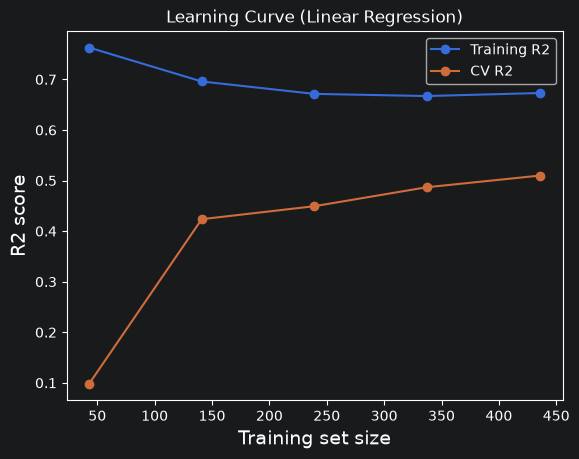

In [51]:
train_sizes, train_scores, test_scores = learning_curve(
    linreg_model,
    X,
    y,
    cv=5,
    scoring='r2',
    train_sizes=np.linspace(.1, 1.0, 5),
    n_jobs=None,
    shuffle=True,
    random_state=42)

train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

plt.figure()
plt.plot(train_sizes, train_mean, label='Training R2', marker='o')
plt.plot(train_sizes, test_mean, 'o-', label='CV R2', )
plt.title('Learning Curve (Linear Regression)')
plt.ylabel('R2 score', fontsize=14)
plt.xlabel('Training set size', fontsize=14)
plt.legend(loc='best')
plt.show()